<a href="https://colab.research.google.com/github/allaalmouiz/from_scratch_recommender/blob/main/MLScale_Practicals.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Building a Recommendation System**
Note: Exploring the dataset of MovieLens, source: [MovieLens Dataset](https://www.kaggle.com/datasets/justsahil/movielens-32m).

Student Name: **Alaa Almouiz F. Moh.**

Course Name: **Machine Learning at Scale.**

Professor Name: **Ulrich Paquet.**


# **Practical 1**
1. Download the MovieLens 32M data set and understand its README.
2. Write a data structure that indexes the data (a) by user and (b) by movie.
3. Plot rating distributions of data.
4. Are there power laws in the data? Is it scale-free? (Note that each user rated at least 20 movies. Truncation will skew the power law that you'd expect…)

## **Step 1:** Download the MovieLens 32M data set and understand its README.

In [1]:
import pandas as pd
import urllib.request
import zipfile

# Downloading the MovieLens32 Dataset
url = 'http://files.grouplens.org/datasets/movielens/ml-32m.zip'
urllib.request.urlretrieve(url, 'ml-32m.zip')

with zipfile.ZipFile('ml-32m.zip', 'r') as zip_ref:
    zip_ref.extractall()

# Loading the ratings.csv file
dataset = pd.read_csv("ml-32m/ratings.csv")

In [2]:
# Exploring the dataset
dataset.head()

,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976
3,1,30,5.0,944249077
4,1,32,5.0,943228858


In [3]:
# General infromation about the dataset
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32000204 entries, 0 to 32000203
Data columns (total 4 columns):
 #   Column     Dtype  
---  ------     -----  
 0   userId     int64  
 1   movieId    int64  
 2   rating     float64
 3   timestamp  int64  
dtypes: float64(1), int64(3)
memory usage: 976.6 MB


### **README.md** summarization

**The dataset structure:**
- 32,000,204 ratings and 2,000,072 tag applications, across 87,585 movies.
- All selected users had rated at least 20 movies.
- Users and movies are only identified by their IDs.

**ratings.csv**: `userId, movieId, rating, timestamp`
- rating goes in half-star steps, from 0.5 to 5.0 stars.
- timestamps are seconds since 1 January 1970.

**tags.csv**: `userId, movieId, tag, timestamp`
- Tags are user-generated metadata about a movie.

**movies.csv**: `movieId, title, genres`
- Errors and inconsistencies may exist in these titles.
- Genres: Action, Adventure, Animation, Children's, Comedy, Crime, Documentary, Drama, Fantasy, Film-Noir, Horror, Musical, Mystery, Romance, Sci-Fi, Thriller, War, Western, (no genres listed).

**links.csv**: `movieId, imdbId, tmdbId`

In [4]:
# Checking the README.md numbers
print("Ratings: ", len(dataset))

Ratings:  32000204


In [5]:
print("Users:", dataset["userId"].nunique())

Users: 200948


In [6]:
print("Movies number:", dataset["movieId"].nunique())

Movies number: 84432


In [7]:
print("The leaset number user ratings is: ", dataset["userId"].value_counts().min())

The leaset number user ratings is:  20


## **Step 2:** Write a data structure that indexes the data (a) by user and (b) by movie

### Indexing:
Using one mapping pass for both the user and the item at the same time.

Starting with:
1. `user_to_index = {}` → dictionary
2. `index_to_user = []` → list
3. `item_to_index = {}` → dictionary
4. `index_to_item = []` → list
5. `data_by_user = []` → list of lists
6. `data_by_item = []` → list of lists

For example, in the ratings we have:

user A, movie a, rating 4

user B, movie c, rating 3

user B, movie a, rating 5

user C, movie c, rating 2

The mapping is as follows:
1. `user_to_index = {"A": 0, "B": 1, "C": 2}` → dictionary
2. `index_to_user = ["A", "B", "C"]` → list
3. `item_to_index = {"a": 0, "c": 1}` → dictionary
4. `index_to_item = ["a", "c"]` → list
5. `data_by_user = [ [(0,4)], [(1,3),(0,5)], [(1,2)] ]` → list of lists
6. `data_by_item = [ [(0,4),(1,5)], [(1,3),(2,2)] ]` → list of lists

The lists start empty, and each time a new user (or movie) shows up I add an empty row `[]` for it, so row `m` always belongs to user `m`.

In [8]:
# The columns of the dataset to iterate through are
dataset.head(0)

,userId,movieId,rating,timestamp


In [9]:
def indexing(df):
  # Initializing the user mappings (user and index)
  user_to_index = {}
  index_to_user = []

  # Initializing the item mappings (item and index)
  item_to_index = {}
  index_to_item = []

  # Initializing the data structures:
  data_by_user = []
  data_by_item = []

  # The datset to iterate through (Index, userId, movieId, rating, timestamp)
  for user, item, rating in df.itertuples(index=False, name=None):
      # New user Entry
      if user not in user_to_index:
        user_to_index[user] = len(index_to_user) # Current length is the new user index (+1)
        index_to_user.append(user)
        data_by_user.append([])

      # New Movie Entry
      if not item in item_to_index:
        item_to_index[item] = len(index_to_item)
        index_to_item.append(item)
        data_by_item.append([])

      # Storing the user and item in the list of list (Not a sparse Matrix)
      m = user_to_index[user]
      n = item_to_index[item]

      data_by_user[m].append((n, rating))
      data_by_item[n].append((m, rating))

  return user_to_index, index_to_user, item_to_index, index_to_item, data_by_user, data_by_item


In [10]:
# Testing the lecture logic

example = pd.DataFrame({
    'user': ['A', 'B', 'B', 'C'],
    'item': ['a', 'c', 'a', 'c'],
    'rating': [4, 3, 5, 2]
})

user_to_index, index_to_user, item_to_index, index_to_item, data_by_user, data_by_item = indexing(example)

print(f"user to index:", user_to_index)
print(f"index to user:", index_to_user)
print(f"item to index:", item_to_index)
print(f"index to item:", index_to_item)
print(f"data by user:", data_by_user)
print(f"data by item:", data_by_item)

user to index: {'A': 0, 'B': 1, 'C': 2}
index to user: ['A', 'B', 'C']
item to index: {'a': 0, 'c': 1}
index to item: ['a', 'c']
data by user: [[(0, 4)], [(1, 3), (0, 5)], [(1, 2)]]
data by item: [[(0, 4), (1, 5)], [(1, 3), (2, 2)]]


In [11]:
# Indexing the MovieLens32

user_to_index, index_to_user, item_to_index, index_to_item, data_by_user, data_by_item = indexing(dataset[["userId", "movieId", "rating"]])

In [12]:
# Checking the indexing results if accurate

M = len(user_to_index)
N = len(item_to_index)

print("Number of users:", M)
print("Number of movies:", N)

Number of users: 200948
Number of movies: 84432


In [13]:
# Checking the number of ratings through the data_by_user list of lists
print("Number of ratings:", sum(len(row) for row in data_by_user))

# Checking the number of ratings through the data_by_item list of lists
print("Number of ratings:", sum(len(row) for row in data_by_item))


Number of ratings: 32000204
Number of ratings: 32000204


## **Step 3:** Plotting the rating distribution of data

We can check three distributions of the ratings in the data.
1. The whole dataset view.
2. The `data_by_user` view, to check the avg rating per user (user behaviour)
3. The `data_by_movie` view, to check the avg rating per movie (movie reputation).

In [14]:
# The whole dataset view

import matplotlib.pyplot as plt

# Counting the number of ratings
ratings_count = dataset["rating"].value_counts()

In [15]:
ratings_count

,count
rating,
4.0,8367654
3.0,6054990
5.0,4596577
3.5,4290105
4.5,2974000
2.0,2028622
2.5,1685386
1.0,946675
1.5,531063


In [16]:
ratings_count = ratings_count.sort_index()

In [17]:
ratings_count

,count
rating,
0.5,525132
1.0,946675
1.5,531063
2.0,2028622
2.5,1685386
3.0,6054990
3.5,4290105
4.0,8367654
4.5,2974000


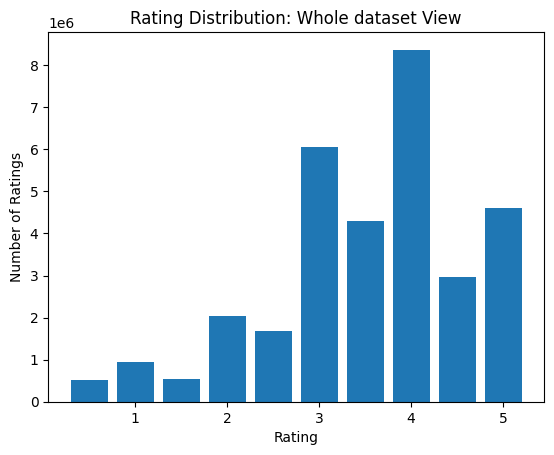

In [18]:
# Plotting the ratings

plt.bar(ratings_count.index, ratings_count.values, width=0.4)
plt.xlabel("Rating")
plt.ylabel("Number of Ratings")
plt.title("Rating Distribution: Whole dataset View")
plt.show()

In [19]:
# Analyzing the Rating Distribution from the Whole dataset view

print(ratings_count)
print(f"Average rating: {round(dataset['rating'].mean(), 1)}")
print(f"Most comon rating: {ratings_count.idxmax()}")
print(f"Least comon rating: {ratings_count.idxmin()}")

rating
0.5     525132
1.0     946675
1.5     531063
2.0    2028622
2.5    1685386
3.0    6054990
3.5    4290105
4.0    8367654
4.5    2974000
5.0    4596577
Name: count, dtype: int64
Average rating: 3.5
Most comon rating: 4.0
Least comon rating: 0.5


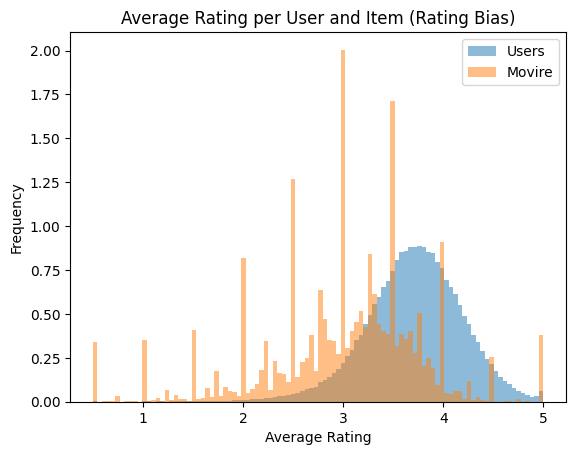

In [20]:
# Analyzing the User and Item Bias (Average Rating Behaviour)
user_means = [sum(rating for user, rating in row) / len(row) for row in data_by_user]
item_means = [sum(rating for item, rating in row) / len(row) for row in data_by_item]

plt.hist(user_means, bins=100, alpha=0.5, density=True, label='Users')
plt.hist(item_means, bins=100, alpha=0.5, density=True, label='Movire')
plt.title('Average Rating per User and Item (Rating Bias)')
plt.xlabel('Average Rating')
plt.ylabel('Frequency')
plt.legend()
plt.show()

From the Distributions:


- **User Perspective:** Average per user is from 3.5 to 4 (Gaussian Distribution).
- **Movie Perspecrive:** Average per movie is spread out.

## **Step 4:** Are there power laws in the data? Is it scale-free?


**Degree of user:** how many movies the user rated.

**Degree of movie:** how many user rated it.



In [21]:
d_users = [len(row) for row in data_by_user]
d_items = [len(row) for row in data_by_item]

In [22]:
import numpy as np

In [23]:
# Analyzing the mean, median, min max for both users and items

print("For users")
print(f"Mean:{round(np.mean(d_users),2)}")
print(f"Median:{np.median(d_users)}")
print(f"Min:{np.min(d_users)}")
print(f"Max:{np.max(d_users)}\n")

print("For items")
print(f"Mean:{round(np.mean(d_items),2)}")
print(f"Median:{np.median(d_items)}")
print(f"Min:{np.min(d_items)}")
print(f"Max:{np.max(d_items)}")

For users
Mean:159.25
Median:73.0
Min:20
Max:33332

For items
Mean:379.01
Median:5.0
Min:1
Max:102929


From the results of the degrees, I've noticed that the **mean is much bigger than the median**. Thefore, most values are small values but there are extreme values, resulting in a **heavy tail**.

For movies (Min:1), a movie stays in the data even if only one user rated it. That’s why movies show the full long tail and users don’t, unlike the users, where we have (Min:20) at least 20+ movies so the tail starts from 20 upwards..

In [24]:
# Counting how many each degree occured
freq_d_users = np.bincount(d_users)
freq_d_items = np.bincount(d_items)

In [25]:
# Index: Ratings, value: How many ratings
freq_d_users

array([0, 0, 0, ..., 0, 0, 1])

In [26]:
degree_users = np.nonzero(freq_d_users)[0]
degree_items = np.nonzero(freq_d_items)[0]

In [27]:
degree_users[1]

np.int64(21)

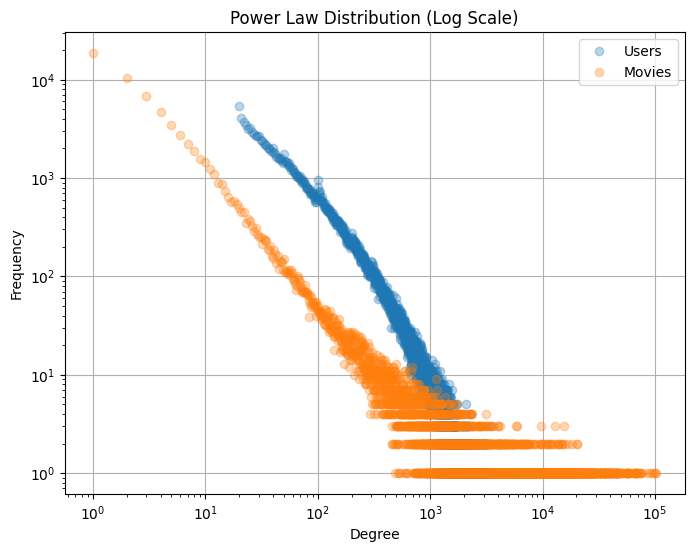

In [28]:
# Plotting the power law (log scale) for X: degree_users & degree_items, Y: filtered freq_d_users & freq_d_items.

plt.figure(figsize=(8, 6))
plt.loglog(degree_users, freq_d_users[degree_users], marker='o', linestyle='', alpha=0.3, label='Users')
plt.loglog(degree_items, freq_d_items[degree_items], marker='o', linestyle='', alpha=0.3, label='Movies')
plt.xlabel('Degree')
plt.ylabel('Frequency')
plt.title('Power Law Distribution (Log Scale)')
plt.legend()
plt.grid(True)
plt.show()

### Are there power laws in the data? Is it scale-free?

The truncation affected the Power Law, since it's starting from 20 till almost 10^3. Regardless of the truncation we could say that it's a scale free network for both users and items (movies).

# **Practical 2**

1. Download a smaller MovieLens dataset to develop and debug with, and again index it.
2. Split the small data set into a training and a test set.
3. You would need two sparse matrices with the same number of rows and columns:
`data_by_user_train` and `data_by_user_test`, `data_by_movie_train` and `data_by_movie_test` (I call them `data_by_item_...`).
4. Build a model that finds maximum likelihood estimate for user + item biases with alternating least squares.
5. Plot the loss function (negative log likelihood) over training iterations, using `data_by_user_train`. It should go down monotonically!
6. Plot the root mean squared error over training iterations, using `data_by_user_train`. What does it converge to?
7. Plot the root mean squared error for `data_by_user_test` after each training iteration. What does it converge to? Does it follow the training error?|

## **Step 1:** Download a smaller MovieLens dataset to develop and debug with, and again index it.


In [29]:
# Chosing the right smaller dataset length almost(100k)

smaller_dataset = dataset[dataset["userId"] < 500]
print(len(smaller_dataset))

80235


In [30]:
smaller_dataset = dataset[dataset["userId"] < 600]
print(len(smaller_dataset))

97076


In [31]:
smaller_dataset = dataset[dataset["userId"] < 640]
print(len(smaller_dataset))

102919


In [32]:
smaller_dataset = dataset[dataset["userId"] < 500]
print(len(smaller_dataset))

80235


In [33]:
smaller_dataset = dataset[dataset["userId"] < 626]
print(len(smaller_dataset))

99994


In [34]:
# Indexing the dataset
user_to_index, index_to_user, item_to_index, index_to_item, data_by_user, data_by_item = indexing(smaller_dataset[["userId", "movieId", "rating"]])

In [35]:
# Number of users and items (movies)
M = len(user_to_index)
N = len(item_to_index)

print("Number of users:", M)
print("Number of movies:", N)

Number of users: 625
Number of movies: 10225


## **Step 2 & 3:** Split the small data set into a training and a test set by building two sparse matrices with the same number of rows and columns.



In [36]:
import random
random.seed(42)

cutoff = 0.2

data_by_user_train = [[] for m in range(M)]
data_by_user_test = [[] for m in range(M)]
data_by_item_train = [[] for n in range(N)]
data_by_item_test = [[] for n in range(N)]

for m in range(M):
  for n, rating in data_by_user[m]:
    if random.random() < cutoff:
      data_by_user_test[m].append((n, rating))
      data_by_item_test[n].append((m, rating))

    else:
      data_by_user_train[m].append((n, rating))
      data_by_item_train[n].append((m, rating))


In [37]:
# Checking the list of lists
data_by_user_test

[[(1, 1.0),
  (7, 5.0),
  (9, 5.0),
  (12, 4.0),
  (13, 3.0),
  (19, 4.0),
  (23, 5.0),
  (26, 2.0),
  (27, 4.0),
  (41, 5.0),
  (44, 1.0),
  (46, 4.0),
  (56, 5.0),
  (58, 1.0),
  (67, 5.0),
  (88, 5.0),
  (89, 5.0),
  (90, 1.0),
  (94, 5.0),
  (100, 5.0),
  (106, 1.0),
  (113, 5.0),
  (119, 1.0),
  (124, 5.0),
  (126, 3.0),
  (131, 4.0),
  (134, 1.0),
  (136, 5.0),
  (139, 2.0)],
 [(153, 2.0),
  (159, 1.0),
  (164, 3.0),
  (167, 5.0),
  (173, 5.0),
  (174, 3.0),
  (181, 4.0),
  (186, 5.0)],
 [(194, 4.0),
  (198, 5.0),
  (200, 3.5),
  (163, 0.5),
  (169, 3.5),
  (172, 4.0),
  (174, 1.0),
  (209, 4.0),
  (178, 4.0),
  (220, 4.0),
  (53, 4.0),
  (227, 2.5),
  (232, 3.0),
  (236, 1.0),
  (237, 4.0),
  (111, 4.0),
  (247, 3.0),
  (136, 3.0),
  (256, 4.0),
  (257, 5.0),
  (263, 5.0),
  (264, 3.0),
  (272, 3.0),
  (277, 4.0),
  (283, 4.0),
  (292, 3.0)],
 [(76, 4.0), (299, 3.0), (308, 2.0), (310, 2.0), (313, 3.0)],
 [(322, 3.0), (201, 3.0), (164, 4.0), (209, 4.0)],
 [(238, 1.0), (330, 5.0),

In [38]:
# Checking the number of ratings
n_train = sum(len(row) for row in data_by_user_train)
n_test  = sum(len(row) for row in data_by_user_test)
n_full = sum(len(row) for row in data_by_user)

print(f"Number of training ratings: {n_train}")
print(f"Number of test ratings: {n_test}")
print(f"Total ratings: {n_train + n_test}")
print(f"Total ratings (full): {n_full}\n")
print(f"Fraction of test set from full set: {round((n_test/n_full),2) *100}%")

Number of training ratings: 79840
Number of test ratings: 20154
Total ratings: 99994
Total ratings (full): 99994

Fraction of test set from full set: 20.0%


## **Step 4:** Build a model that finds Maximum Likelihood Estimate (MLE) for user + item biases with alternating least squares.

rating = 0[uT.v = 0]+ bm + bn

In [39]:
def compute_loss_and_rmse(data_by_user):
  total = 0     # Sum of SE
  count = 0     # Number of rating

  for m in range(M):
    for n, rating in data_by_user[m]:
      r_predicted = user_biases[m] + item_biases[n]
      total += (rating - r_predicted) ** 2
      count += 1

  loss = (lam/2)* total + (gamma/2) * np.sum(user_biases ** 2) + (gamma/2) * np.sum(item_biases ** 2)
  rmse = np.sqrt(total/count)

  return loss, rmse

In [40]:
# Intializing the compute_loss_and_rmse dependants
user_biases = np.zeros(M)
item_biases = np.zeros(N)

n_iterations = 20

lam = 1        # Noise precision
gamma = 0      # Biases regularizer

train_losses = []
test_losses = []
train_rmse = []
test_rmse = []


# Training the model for user+item biases using ALS
for iteration in range(n_iterations):
  print(f"Iteration {iteration + 1}/{n_iterations}")

  # 1. Loop over users -> update user_biases, fix for items
  for m in range(M):
    bias = 0
    item_count = 0
    for n, rating in data_by_user_train[m]:
      bias += lam * (rating - item_biases[n])
      item_count += 1
    user_biases[m] = bias / (lam * item_count + gamma) if item_count > 0 else 0.0


  # 2. Loop over items (movies) -> update item_biases, fix for users
  for n in range(N):
    bias = 0
    user_count = 0
    for m, rating in data_by_item_train[n]:
      bias += lam * (rating - user_biases[m])
      user_count += 1
    item_biases[n] = bias / (lam * user_count + gamma) if user_count > 0 else 0.0

  # 3. Computing losses and RMSE
  train_loss, train_rmse_value = compute_loss_and_rmse(data_by_user_train)
  test_loss, test_rmse_value = compute_loss_and_rmse(data_by_user_test)

  train_losses.append(train_loss)
  test_losses.append(test_loss)
  train_rmse.append(train_rmse_value)
  test_rmse.append(test_rmse_value)

  print(f"loss {train_loss:.1f}, train RMSE {train_rmse_value:.4f}, test RMSE {test_rmse_value:.4f}\n")


Iteration 1/20
loss 27030.5, train RMSE 0.8229, test RMSE 0.9355

Iteration 2/20
loss 26119.0, train RMSE 0.8089, test RMSE 0.9248

Iteration 3/20
loss 26040.8, train RMSE 0.8077, test RMSE 0.9247

Iteration 4/20
loss 26031.8, train RMSE 0.8075, test RMSE 0.9249

Iteration 5/20
loss 26030.5, train RMSE 0.8075, test RMSE 0.9250

Iteration 6/20
loss 26030.3, train RMSE 0.8075, test RMSE 0.9250

Iteration 7/20
loss 26030.2, train RMSE 0.8075, test RMSE 0.9250

Iteration 8/20
loss 26030.2, train RMSE 0.8075, test RMSE 0.9250

Iteration 9/20
loss 26030.2, train RMSE 0.8075, test RMSE 0.9250

Iteration 10/20
loss 26030.2, train RMSE 0.8075, test RMSE 0.9250

Iteration 11/20
loss 26030.2, train RMSE 0.8075, test RMSE 0.9250

Iteration 12/20
loss 26030.2, train RMSE 0.8075, test RMSE 0.9250

Iteration 13/20
loss 26030.2, train RMSE 0.8075, test RMSE 0.9250

Iteration 14/20
loss 26030.2, train RMSE 0.8075, test RMSE 0.9250

Iteration 15/20
loss 26030.2, train RMSE 0.8075, test RMSE 0.9250

Iter

## **Step 5:** Plot the loss function (negative log likelihood) over training iterations, using `data_by_user_train`. It should go down monotonically!

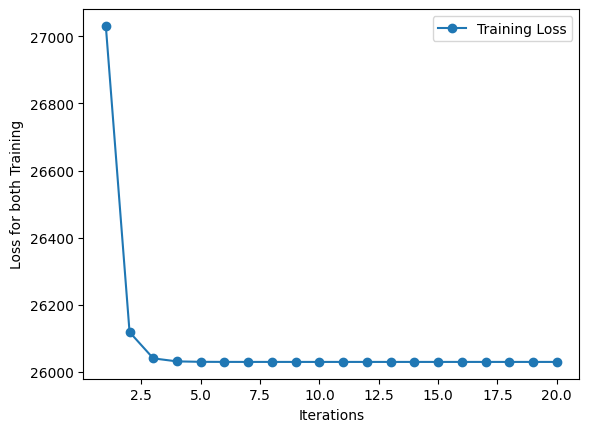

In [41]:
# Ploting the loss function for training and testing
iterations = range(1, n_iterations + 1)
plt.plot(iterations, train_losses, label='Training Loss', marker='o', linestyle='-')
plt.xlabel("Iterations")
plt.ylabel("Loss for both Training")
plt.legend()
plt.show()

## **Step 6 & 7:** Plot the RMSE over training and testing iterations, using `data_by_user_train` and `data_by_user_test` What does it converge to? Does the testing follow the training error?|

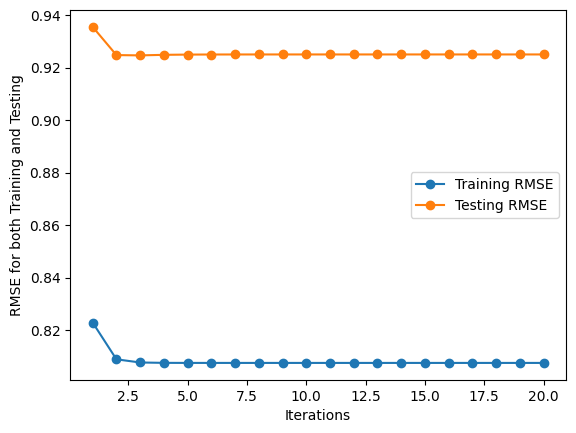

In [42]:
# Plotting the RMSE for training
plt.plot(iterations, train_rmse, label='Training RMSE', marker='o', linestyle='-')
plt.plot(iterations, test_rmse, label='Testing RMSE', marker='o', linestyle='-')
plt.xlabel("Iterations")
plt.ylabel("RMSE for both Training and Testing")
plt.legend()
plt.show()

# Class Practical:

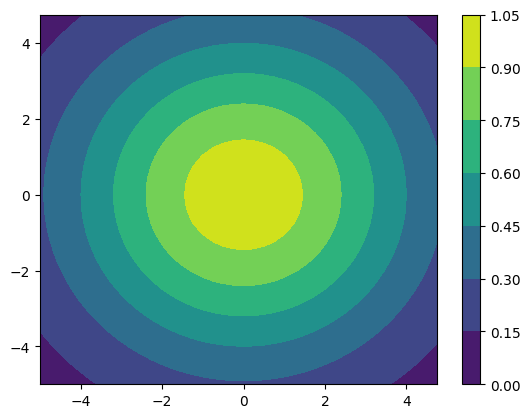

In [43]:
# Plotting two dimentsional for u and v

import matplotlib.pyplot as plt
import numpy as np

tau = 0.1 # Regularizer term
lam = 0.25
r = 1

u = np.arange(-5, 5, 0.25)
v = np.arange(-5, 5, 0.25)

U,V = np.meshgrid(u,v)
P = np.exp( -0.5 * tau * ((U**2) + (V**2)) )

surf = plt.contourf(U,V,P)
plt.colorbar(surf)
plt.show()

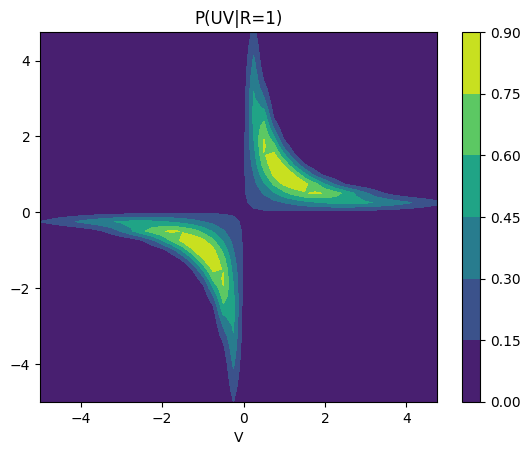

In [44]:
# Plotting two dimentsional for u and v

import matplotlib.pyplot as plt
import numpy as np

tau = 0.14 #
lam = 4
r = 1

u = np.arange(-5, 5, 0.25)
v = np.arange(-5, 5, 0.25)

U,V = np.meshgrid(u,v)
P = np.exp( (-0.5 * tau * (U**2 + V**2) - 0.5 * lam * (r - (U*V))**2))

surf = plt.contourf(U,V,P)
plt.colorbar(surf)
plt.xlabel("P")
plt.xlabel("V")

plt.title("P(UV|R=1)")
plt.show()

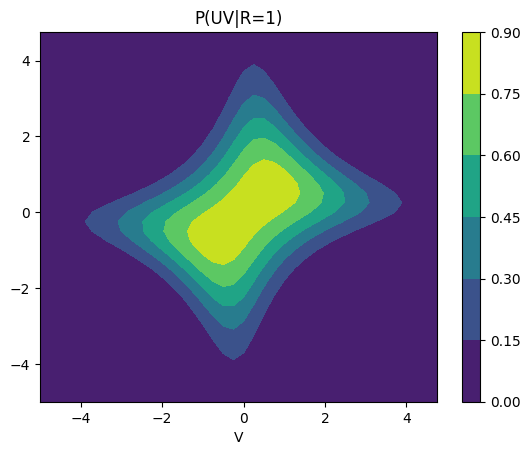

In [45]:
# Plotting two dimentsional for u and v

import matplotlib.pyplot as plt
import numpy as np

tau = 0.25
lam = 0.35
r = 1

u = np.arange(-5, 5, 0.25)
v = np.arange(-5, 5, 0.25)

U,V = np.meshgrid(u,v)
P = np.exp( (-0.5 * tau * (U**2 + V**2) - 0.5 * lam * (r - (U*V))**2))

surf = plt.contourf(U,V,P)
plt.colorbar(surf)
plt.xlabel("P")
plt.xlabel("V")
plt.title("P(UV|R=1)")
plt.show()

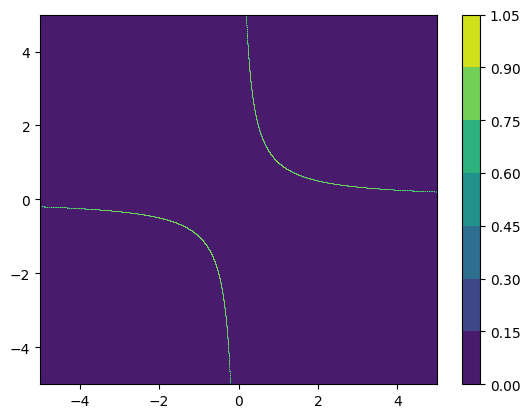

In [46]:
# Plotting two dimentsional for u and v

import matplotlib.pyplot as plt
import numpy as np

tau = 0.01 # Regularizer term
lam = 0.25
r = 1

u = np.arange(-5, 5, 0.0025)
v = np.arange(-5, 5, 0.0025)

U,V = np.meshgrid(u,v)
P = np.exp( (-0.5 * tau * (U**2 + V**2) - 0.5 * lam * (1000* ( r - (U*V)))**2))

surf = plt.contourf(U,V,P)
plt.colorbar(surf)
plt.show()


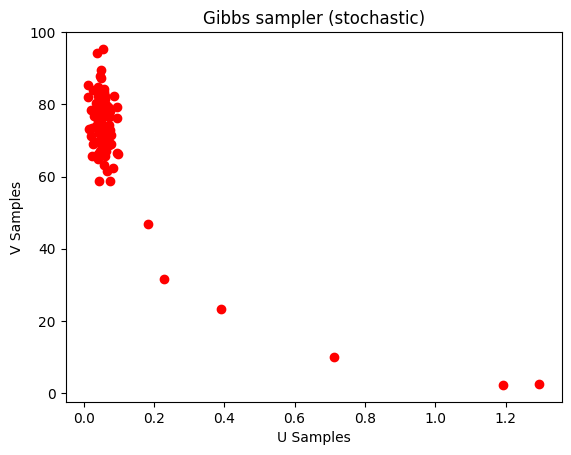

In [47]:
import numpy as np
import matplotlib.pyplot as plt

# U and V intialization
steps = 100
tau = 0.02
lam = 0.4
r = 4

# Random starting point for u and v
u = -1
v = 3
u_samples, v_samples = [], []

for i in range(steps):
  # Sampling U given V
  var_u = 1/(lam * v**2 + tau)
  mean_u = var_u * lam * r * v
  u = np.random.normal(mean_u, np.sqrt(var_u))

  # Sampling V given U
  var_v = 1/(lam * u**2 + tau)
  mean_v = var_v * lam * r
  v = np.random.normal(mean_v, np.sqrt(var_v))

  u_samples.append(u)
  v_samples.append(v)

# Plotting the u and v gaussian
plt.scatter(u_samples, v_samples, color="r")
plt.xlabel("U Samples")
plt.ylabel("V Samples")
plt.title("Gibbs sampler (stochastic)")
plt.show()

# **Class Practical**

In [48]:
# Coding Variational Bayes
# Initialization

import numpy as np
import matplotlib.pyplot as plt

lam = 4
tau = 0.02
r = 1
steps = 20

mean_history_u, var_history_u=[], []
mean_history_v, var_history_v=[], []

# Mean and Varience intializations
mean_v, var_v = 1, 1
mean_u, var_u = 1, 1

for step in range(steps):
  var_v = 1/(lam * (mean_v)**2 + (var_v)**2) + tau
  mean_v = var_v  * lam * r * mean_v

  var_u = 1/(lam * (mean_u)**2 + (var_u)**2) + tau
  mean_u = var_u  * lam * r * mean_u

  mean_history_u.append(mean_u)
  mean_history_v.append(mean_v)

  var_history_v.append(var_v)
  var_history_u.append(var_u)

In [49]:
mean_history_u

[0.88,
 1.189281118881119,
 0.919356486778882,
 1.1493809650055262,
 0.9461921798780489,
 1.120209163819838,
 0.9669945964009912,
 1.0987733725958004,
 0.9830498845497102,
 1.0828893518459866,
 0.9953932379078054,
 1.07104936516907,
 1.0048524772936283,
 1.062186326008479,
 1.0120828239100006,
 1.0555313013184977,
 1.017598200177335,
 1.0505229423529092,
 1.0217986619541748,
 1.0467475324690236]

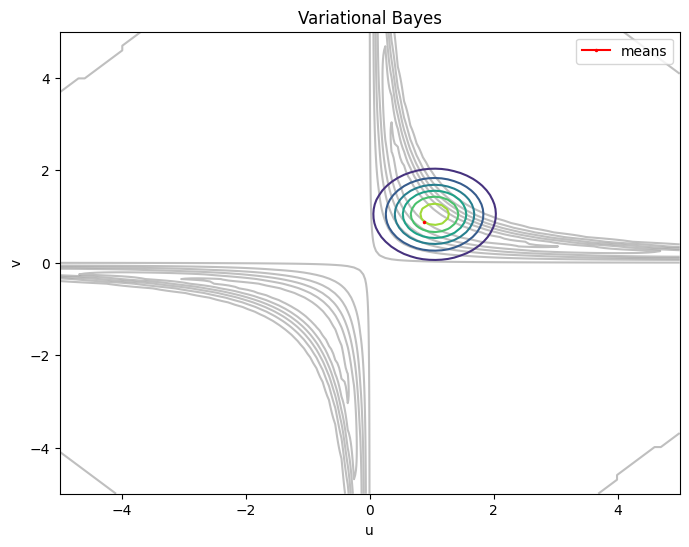

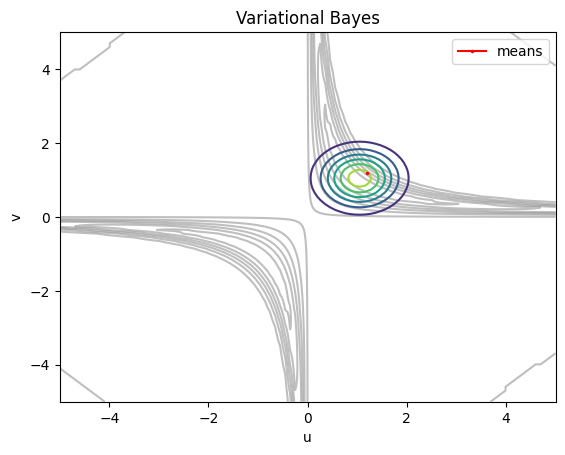

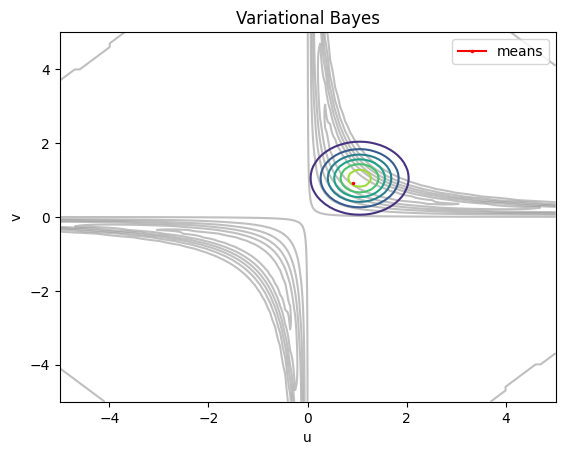

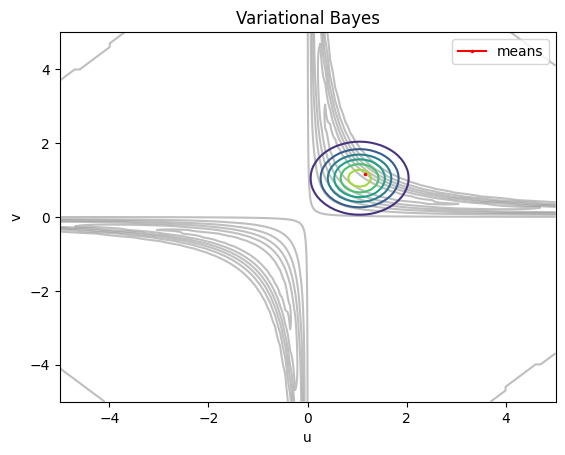

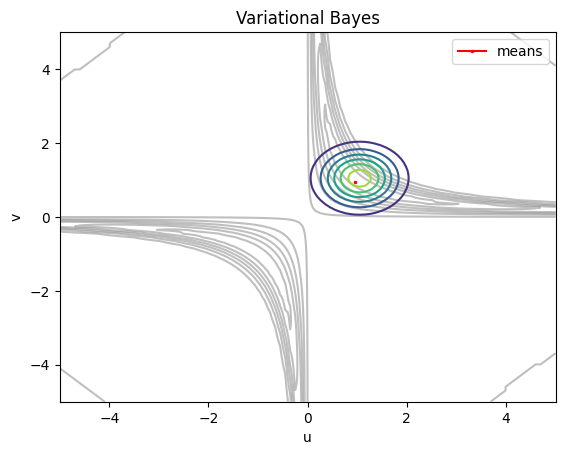

In [50]:
# Plotting the gaussians
x = np.linspace(-5, 5, 100)
U,V = np.meshgrid(x,x)

P = np.exp((-0.5 * tau * (U**2 + V**2) - 0.5 * lam * (r - (U*V))**2))
Q = np.exp( -0.5 * (U - mean_u)**2 / var_u -0.5 * (V - mean_v)**2 / var_v )

plt.figure(figsize=(8, 6))
for i in range(5):
  plt.contour(U, V, P, colors="gray", alpha=0.5)
  plt.contour(U, V, Q)
  plt.plot( mean_history_u[i], mean_history_v[i], "r.-", markersize=3, label="means" )
  plt.xlabel("u")
  plt.ylabel("v")
  plt.title("Variational Bayes")
  plt.legend()
  plt.show()


#**Practical 3**


1. Add user and item factors (latent trait vectors or matrices U and V)
2. Add a sensible regularizer to your loss function.
3. Build a model that finds maximum likelihood estimate for user + item biases + latent trait vectors / factors with alternating least squares using
`data_by_user_train` and `data_by_item_train`.
4. Plot the loss function (negative log likelihood) over training iterations using `data_by_user_train`. It should go down monotonically!
5. Plot the root mean squared error over training iterations using
`data_by_user_train` and `data_by_user_test` . What does it converge to?

## **Steps 1, 2 & 3:** Add user and item factors (latent trait vectors or matrices U and V), Add a sensible regularizer to your loss function and Build a model that finds maximum likelihood estimate for user + item biases + latent trait vectors / factors with ALS.

In [51]:
# Initiallizing the U and V to follow a gaussian distribution
K = 20  # Dimensionality of U and V

random_seed = 42
rng = np.random.default_rng(random_seed)
U = rng.normal(0, 1/np.sqrt(K), size=(M, K))
V = rng.normal(0, 1/np.sqrt(K), size=(N, K))

In [52]:
# Checking the latent vector U
print(U)
print(f"Shape of U (User) is {U.shape}")
print(f"Shape of V (Items) is {V.shape}")

[[ 0.06813681 -0.23254752  0.16780599 ... -0.21441267  0.19642746
  -0.01116377]
 [-0.04133648 -0.15226047  0.27336855 ... -0.1878647  -0.1843596
   0.14547697]
 [ 0.16619669  0.12145299 -0.14881249 ...  0.33427904 -0.19360572
   0.21651362]
 ...
 [-0.31508134  0.10853118  0.38713591 ...  0.14211209 -0.00924426
  -0.20040235]
 [-0.08112356 -0.17698708  0.0661633  ... -0.03254297  0.18828825
  -0.11362247]
 [ 0.09832917 -0.2421071   0.17442635 ... -0.08000758 -0.37147169
  -0.00546411]]
Shape of U (User) is (625, 20)
Shape of V (Items) is (10225, 20)


For the previous loss function, I will change `r_predicted` and the `loss`, adding the U, V, and tau.

In [53]:
def compute_loss_and_rmse(data_by_user):
  total = 0     # Sum of SE
  count = 0     # Number of rating

  for m in range(M):
    for n, rating in data_by_user[m]:
      r_predicted = U[m]@V[n] + user_biases[m] + item_biases[n]
      total += (rating - r_predicted) ** 2
      count += 1

  loss = (lam/2)* total + (gamma/2) * np.sum(user_biases ** 2) + (gamma/2) * np.sum(item_biases ** 2) + (tau/2) * (np.sum(U ** 2) + np.sum(V ** 2))
  rmse = np.sqrt(total/count)

  return loss, rmse

In [54]:
# Intializing the compute_loss_and_rmse dependants
user_biases = np.zeros(M)
item_biases = np.zeros(N)

n_iterations = 20

lam = 1        # Noise precision
gamma = 0      # Biases regularizer
tau = 20       # U & V vectors regularizer

train_losses = []
test_losses = []
train_rmse = []
test_rmse = []


# Training the model for user+item biases + trait vectors using ALS
for iteration in range(n_iterations):
  print(f"Iteration {iteration + 1}/{n_iterations}")

  # 1. Loop over users -> update user_biases and U, fix for items
  for m in range(M):

    # User bias
    bias = 0
    item_count = 0
    for n, rating in data_by_user_train[m]:
      bias += lam * (rating - (U[m] @ V[n] + item_biases[n]))
      item_count += 1
    user_biases[m] = bias / (lam * item_count + gamma) if item_count > 0 else 0.0

    # Then the user vector, using the new bias
    A = tau * np.eye(K)
    b = np.zeros(K)
    for n, rating in data_by_user_train[m]:
      A += lam * np.outer(V[n], V[n])
      b += lam * V[n] * (rating - user_biases[m] - item_biases[n])
    U[m] = np.linalg.solve(A, b)


  # 2. Loop over items (movies) -> update item_biases and V, fix for users
  for n in range(N):

    # Item bias first
    bias = 0
    user_count = 0
    for m, rating in data_by_item_train[n]:
      bias += lam * (rating - (U[m] @ V[n] + user_biases[m]))
      user_count += 1
    item_biases[n] = bias / (lam * user_count + gamma) if user_count > 0 else 0.0

    # Then the item vector, using the new bias
    A = tau * np.eye(K)
    b = np.zeros(K)
    for m, rating in data_by_item_train[n]:
      A += lam * np.outer(U[m], U[m])
      b += lam * U[m] * (rating - user_biases[m] - item_biases[n])
    V[n] = np.linalg.solve(A, b)

  # 3. Computing losses and RMSE
  train_loss, train_rmse_value = compute_loss_and_rmse(data_by_user_train)
  test_loss, test_rmse_value = compute_loss_and_rmse(data_by_user_test)

  train_losses.append(train_loss)
  test_losses.append(test_loss)
  train_rmse.append(train_rmse_value)
  test_rmse.append(test_rmse_value)

  print(f"loss {train_loss:.1f}, train RMSE {train_rmse_value:.4f}, test RMSE {test_rmse_value:.4f}\n")

Iteration 1/20
loss 27435.3, train RMSE 0.8141, test RMSE 0.9340

Iteration 2/20
loss 25910.7, train RMSE 0.7923, test RMSE 0.9222

Iteration 3/20
loss 25423.6, train RMSE 0.7692, test RMSE 0.9182

Iteration 4/20
loss 25235.3, train RMSE 0.7536, test RMSE 0.9157

Iteration 5/20
loss 25181.0, train RMSE 0.7465, test RMSE 0.9145

Iteration 6/20
loss 25161.4, train RMSE 0.7431, test RMSE 0.9139

Iteration 7/20
loss 25152.8, train RMSE 0.7412, test RMSE 0.9136

Iteration 8/20
loss 25148.5, train RMSE 0.7402, test RMSE 0.9134

Iteration 9/20
loss 25146.0, train RMSE 0.7396, test RMSE 0.9133

Iteration 10/20
loss 25144.4, train RMSE 0.7391, test RMSE 0.9132

Iteration 11/20
loss 25143.3, train RMSE 0.7388, test RMSE 0.9131

Iteration 12/20
loss 25142.5, train RMSE 0.7386, test RMSE 0.9131

Iteration 13/20
loss 25141.9, train RMSE 0.7384, test RMSE 0.9130

Iteration 14/20
loss 25141.4, train RMSE 0.7382, test RMSE 0.9130

Iteration 15/20
loss 25141.0, train RMSE 0.7381, test RMSE 0.9130

Iter

## **Step 4:** Plot the loss function (negative log likelihood) over training iterations using `data_by_user_train`. It should go down monotonically!

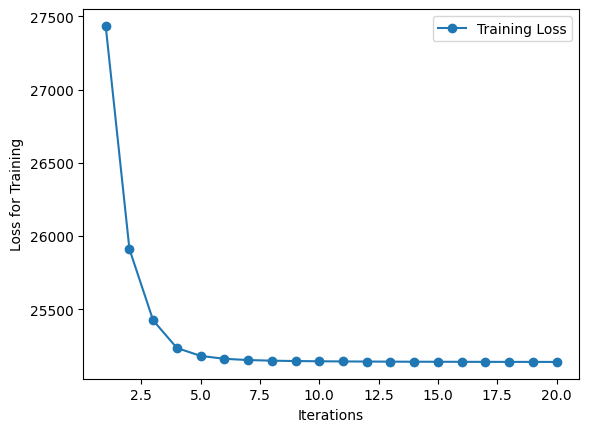

In [55]:
# Ploting the loss function for training
iterations = range(1, n_iterations + 1)
plt.plot(iterations, train_losses, label='Training Loss', marker='o', linestyle='-')
plt.xlabel("Iterations")
plt.ylabel("Loss for Training")
plt.legend()
plt.show()

## **Step 5:** Plot the root mean squared error over training iterations using `data_by_user_train` and `data_by_user_test` . What does it converge to?

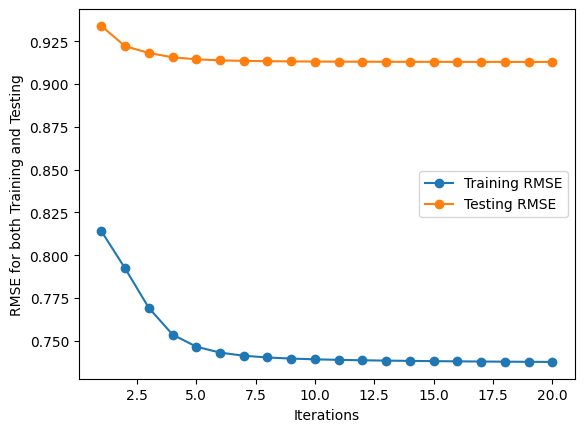

In [56]:
# Plotting the RMSE for training and testing
plt.plot(iterations, train_rmse, label='Training RMSE', marker='o', linestyle='-')
plt.plot(iterations, test_rmse, label='Testing RMSE', marker='o', linestyle='-')
plt.xlabel("Iterations")
plt.ylabel("RMSE for both Training and Testing")
plt.legend()
plt.show()

**Training RMSE** converges to about **0.73** after 10 iterations (biases only: 0.8).

**Testing RMSE** converges to about **0.91** (biases only: 0.92).

- Adding the trait vectors improves both: they capture each user's personal taste, which the biases alone can't.
- The testing RMSE follows the shape of the training curve (fast drop, then flat), but stays clearly higher.
- The loss decreases at every iteration, as expected for ALS.

# **Practical 4**
1. Split the MovieLens 32M dataset into a training and a test set (plus a validation set to choose λ, τ, γ, K and the number of iterations).
2. Use only the training set to fit the parameters, and plot the training and test RMSE on the same axis. Where does overfitting happen?
3. Is there more overfitting with K = 20 than with K = 10? For which users? Is there underfitting anywhere? How do λ and τ change this?
4. Train on all 32M ratings, with an implementation that is faster than the naive one.
5. Show that if a user liked movie X, the recommendations make sense (dummy user).
6. Which movies are the most and least polarizing?

## **Step 0:** Making the code fast enough for 32M ratings
My Practical 3 code loops over Python lists of tuples. That is fine for 100k ratings, but 32M ratings are 320 times more data. I keep the same idea as `data_by_user`, but store it as three numpy arrays (compressed sparse rows, CSR):
- `ptr`: user m's ratings are at positions `ptr[m]` to `ptr[m+1]`,
- `idx`: the movie index of every rating, user after user,
- `ratings`: the ratings, in the same order.

For the example of Practical 1, `data_by_user = [[(0, 4)], [(1, 3), (0, 5)], [(1, 2)]]` becomes `ptr = [0, 1, 3, 4]`, `idx = [0, 1, 0, 1]` and `ratings = [4, 3, 5, 2]`. The same is done by movie. The ALS loops are compiled with `numba`, and all users (then all movies) are updated in parallel: each user's update only needs its own ratings and the fixed movie parameters.

In [57]:
import gc
import json
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numba import njit, prange

os.makedirs("figures", exist_ok=True)
plt.rcParams.update({"figure.figsize": (3.4, 2.4), "font.size": 8,
                     "legend.fontsize": 7, "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.bbox": "tight"})

results = {}      # all the numbers that go into the report


def save():
    json.dump(results, open("results.json", "w"), indent=1)

In [58]:
def to_csr(rows, cols, values, n_rows):
    order = np.argsort(rows, kind="stable")
    ptr = np.zeros(n_rows + 1, dtype=np.int64)
    ptr[1:] = np.cumsum(np.bincount(rows, minlength=n_rows))
    return ptr, cols[order].astype(np.int32), values[order].astype(np.float64)


# Checking it on the example of Practical 1 (users A, B, C; movies a, c)
print(to_csr(np.array([0, 1, 1, 2]), np.array([0, 1, 0, 1]),
             np.array([4.0, 3.0, 5.0, 2.0]), 3))

(array([0, 1, 3, 4]), array([0, 1, 0, 1], dtype=int32), array([4., 3., 5., 2.]))


## **Step 1:** Training, validation and test sets
As in Practical 2 every rating is sent to a set at random, but now in three parts: **80% training** (to fit U, V and the biases), **10% validation** (to choose the hyperparameters) and **10% test** (used only once, at the end).

As an additional split I also make a **time split**: for each user, the last 10% of the ratings in time go to the test set and the 10% before that to validation. This is closer to real life, where we predict the future from the past.

In [59]:
# Indexing all the ratings: pd.factorize gives every new user (or movie) the
# next free index, in order of first appearance, like my indexing() function
user_index, index_to_user = pd.factorize(dataset["userId"])
item_index, index_to_item = pd.factorize(dataset["movieId"])
user_index = user_index.astype(np.int32)
item_index = item_index.astype(np.int32)
all_ratings = dataset["rating"].to_numpy()
timestamps = dataset["timestamp"].to_numpy()
M, N = len(index_to_user), len(index_to_item)
del dataset          # the arrays above are all I need from now on
gc.collect()
print("Users:", M, " Movies:", N, " Ratings:", len(all_ratings))

# Random split: 0 = train, 1 = validation, 2 = test
rng = np.random.default_rng(42)
p = rng.random(len(all_ratings))
split_random = np.where(p < 0.8, 0, np.where(p < 0.9, 1, 2)).astype(np.int8)
del p


def time_split():
    order = np.lexsort((timestamps, user_index))     # by user, then by time
    counts = np.bincount(user_index, minlength=M)
    position = np.arange(len(order)) - np.repeat(np.cumsum(counts) - counts,
                                                 counts)
    fraction = position / np.repeat(counts, counts)  # 0 = oldest rating
    split = np.empty(len(order), dtype=np.int8)
    split[order] = np.where(fraction < 0.8, 0, np.where(fraction < 0.9, 1, 2))
    return split


def make_sets(split):
    sets = {}
    for part, name in enumerate(["train", "val", "test"]):
        mask = split == part
        u, i, r = user_index[mask], item_index[mask], all_ratings[mask]
        sets[name] = {"by_user": to_csr(u, i, r, M),
                      "by_item": to_csr(i, u, r, N), "n": int(mask.sum())}
    return sets


data = make_sets(split_random)
for name in ["train", "val", "test"]:
    print(f"{name}: {data[name]['n']:,d} ratings")
cold_movies = int((np.diff(data["train"]["by_item"][0]) == 0).sum())
print("Movies with no training ratings:", cold_movies)
results["split"] = {name: data[name]["n"] for name in ["train", "val", "test"]}
results["split"]["cold_movies"] = cold_movies

Users: 200948  Movies: 84432  Ratings: 32000204
train: 25,601,250 ratings
val: 3,198,729 ratings
test: 3,200,225 ratings
Movies with no training ratings: 4166


## **Step 2:** ALS on the training set
The model is the one of Practical 3 plus the global mean μ of the training ratings: r̂ = μ + b_m + b_n + u_m·v_n. In Practicals 2 and 3 I used γ = 0, so the user biases could absorb the mean. With γ > 0 the prior pulls the biases towards 0, which without μ would mean "towards 0 stars".

The updates are the same as in Practical 3 (first the bias, then the trait vector). The movie update is the same function as the user update with U and V swapped. `prior_X` and `prior_b` are the prior means (zero here; they would let me add movie features such as genres later).

In [60]:
@njit(fastmath=True)
def dot(a, b):
    total = 0.0
    for k in range(a.shape[0]):
        total += a[k] * b[k]
    return total


@njit(parallel=True, fastmath=True)
def update(ptr, idx, ratings, X, x_biases, Y, y_biases, mu, lam, tau, gamma,
           prior_X, prior_b):
    K = X.shape[1]
    for m in prange(X.shape[0]):
        start, end = ptr[m], ptr[m + 1]

        # 1. The bias, with the current trait vector
        total = 0.0
        for j in range(start, end):
            total += ratings[j] - mu - y_biases[idx[j]] - dot(X[m], Y[idx[j]])
        denominator = lam * (end - start) + gamma
        if denominator > 0:
            x_biases[m] = (lam * total + gamma * prior_b[m]) / denominator
        else:                           # no ratings and gamma = 0
            x_biases[m] = prior_b[m]

        # 2. The trait vector, with the new bias
        if K > 0:
            A = tau * np.eye(K)
            b = tau * prior_X[m].copy()
            for j in range(start, end):
                n = idx[j]
                residual = ratings[j] - mu - x_biases[m] - y_biases[n]
                for k1 in range(K):
                    b[k1] += lam * Y[n, k1] * residual
                    for k2 in range(K):
                        A[k1, k2] += lam * Y[n, k1] * Y[n, k2]
            X[m] = np.linalg.solve(A, b)


@njit(parallel=True, fastmath=True)
def squared_errors(ptr, idx, ratings, X, x_biases, Y, y_biases, mu):
    # sum of squared errors of every row (user or movie)
    out = np.zeros(X.shape[0])
    for m in prange(X.shape[0]):
        for j in range(ptr[m], ptr[m + 1]):
            n = idx[j]
            r_predicted = mu + x_biases[m] + y_biases[n] + dot(X[m], Y[n])
            out[m] += (ratings[j] - r_predicted) ** 2
    return out


def rmse(sets, name, params):
    U, V, user_biases, item_biases, mu = params
    total = squared_errors(*sets[name]["by_user"], U, user_biases, V,
                           item_biases, mu).sum()
    return np.sqrt(total / max(sets[name]["n"], 1)), total


loss_checks = []     # does the training loss go down in every run?


def train(sets, K, lam=1.0, tau=20.0, gamma=5.0, n_iterations=21,
          use_mu=True, parts=("train", "val", "test"), seed=42):
    by_user, by_item = sets["train"]["by_user"], sets["train"]["by_item"]
    M, N = len(by_user[0]) - 1, len(by_item[0]) - 1
    rng = np.random.default_rng(seed)
    U = rng.normal(0, 1 / np.sqrt(max(K, 1)), size=(M, K))
    V = rng.normal(0, 1 / np.sqrt(max(K, 1)), size=(N, K))
    user_biases, item_biases = np.zeros(M), np.zeros(N)
    mu = float(np.mean(by_user[2])) if use_mu else 0.0
    zeros_U, zeros_V = np.zeros((M, K)), np.zeros((N, K))

    history = {name: [] for name in parts}
    history["loss"], history["time"] = [], []
    for iteration in range(n_iterations):
        start = time.time()
        # 1. Loop over users -> update user biases and U, movies fixed
        update(*by_user, U, user_biases, V, item_biases, mu, lam, tau, gamma,
               zeros_U, np.zeros(M))
        # 2. Loop over movies -> update movie biases and V, users fixed
        update(*by_item, V, item_biases, U, user_biases, mu, lam, tau, gamma,
               zeros_V, np.zeros(N))
        history["time"].append(time.time() - start)

        # 3. Loss and RMSE
        params = (U, V, user_biases, item_biases, mu)
        for name in parts:
            value, total = rmse(sets, name, params)
            history[name].append(value)
            if name == "train":
                history["loss"].append(
                    lam / 2 * total
                    + tau / 2 * (np.sum(U ** 2) + np.sum(V ** 2))
                    + gamma / 2 * (np.sum(user_biases ** 2)
                                   + np.sum(item_biases ** 2)))
    if len(history["loss"]) > 1:
        loss = np.array(history["loss"])
        loss_checks.append(bool(np.all(np.diff(loss) <= 1e-9 * loss[:-1])))
    return (U, V, user_biases, item_biases, mu), history

### Speed: my Practical 3 code against the new code
One ALS iteration with K = 20, τ = 20 (as in Practical 3): my Practical 3 loop on the small training set of Practical 2, the new code on the same data, and the new code on the 32M training set.

In [61]:
def practical3_iteration(U, V, user_biases, item_biases, lam, tau, gamma):
    # one iteration of my Practical 3 loop (Python lists), only for timing
    K = U.shape[1]
    for m in range(len(data_by_user_train)):
        bias, item_count = 0, 0
        for n, rating in data_by_user_train[m]:
            bias += lam * (rating - (U[m] @ V[n] + item_biases[n]))
            item_count += 1
        user_biases[m] = bias / (lam * item_count + gamma) if item_count else 0
        A, b = tau * np.eye(K), np.zeros(K)
        for n, rating in data_by_user_train[m]:
            A += lam * np.outer(V[n], V[n])
            b += lam * V[n] * (rating - user_biases[m] - item_biases[n])
        U[m] = np.linalg.solve(A, b)
    for n in range(len(data_by_item_train)):
        bias, user_count = 0, 0
        for m, rating in data_by_item_train[n]:
            bias += lam * (rating - (U[m] @ V[n] + user_biases[m]))
            user_count += 1
        item_biases[n] = bias / (lam * user_count + gamma) if user_count else 0
        A, b = tau * np.eye(K), np.zeros(K)
        for m, rating in data_by_item_train[n]:
            A += lam * np.outer(U[m], U[m])
            b += lam * U[m] * (rating - user_biases[m] - item_biases[n])
        V[n] = np.linalg.solve(A, b)


M_small, N_small = len(data_by_user_train), len(data_by_item_train)
rng = np.random.default_rng(42)
U_s = rng.normal(0, 1 / np.sqrt(20), size=(M_small, 20))
V_s = rng.normal(0, 1 / np.sqrt(20), size=(N_small, 20))
start = time.time()
practical3_iteration(U_s, V_s, np.zeros(M_small), np.zeros(N_small), 1, 20, 0)
time_naive_small = time.time() - start

# the same small training set as CSR arrays
rows = np.array([m for m in range(M_small) for _ in data_by_user_train[m]])
cols = np.array([n for row in data_by_user_train for n, _ in row])
vals = np.array([r for row in data_by_user_train for _, r in row], float)
small = {"train": {"by_user": to_csr(rows, cols, vals, M_small),
                   "by_item": to_csr(cols, rows, vals, N_small),
                   "n": len(vals)}}
train(small, 20, gamma=0, n_iterations=1, parts=())     # compiling numba
time_fast_small = np.mean(train(small, 20, gamma=0, n_iterations=3,
                                parts=())[1]["time"])
time_fast_big = np.mean(train(data, 20, gamma=0, n_iterations=3,
                              parts=())[1]["time"])
time_naive_big = time_naive_small * data["train"]["n"] / len(vals)

results["speed"] = {"small_ratings": len(vals),
                    "big_ratings": data["train"]["n"],
                    "naive_small": time_naive_small,
                    "fast_small": time_fast_small, "fast_big": time_fast_big,
                    "naive_big": time_naive_big}
print(f"Practical 3 code, {len(vals):,d} ratings: {time_naive_small:.2f} s")
print(f"New code, same data: {time_fast_small:.3f} s")
print(f"New code, {data['train']['n']:,d} ratings: {time_fast_big:.1f} s")
print(f"Practical 3 code on 32M (extrapolated): {time_naive_big / 60:.0f} min")

Practical 3 code, 79,840 ratings: 3.05 s
New code, same data: 0.112 s
New code, 25,601,250 ratings: 21.6 s
Practical 3 code on 32M (extrapolated): 16 min


## **Step 3:** Biases only (K = 0): choosing γ
I choose the bias regularizer γ on the validation set, with and without μ.

with_mu, gamma=0: val RMSE 0.8560
with_mu, gamma=1: val RMSE 0.8555
with_mu, gamma=2: val RMSE 0.8553
with_mu, gamma=5: val RMSE 0.8553
with_mu, gamma=10: val RMSE 0.8558
with_mu, gamma=20: val RMSE 0.8575
with_mu, gamma=50: val RMSE 0.8633
without_mu, gamma=0: val RMSE 0.8560
without_mu, gamma=1: val RMSE 0.8562
without_mu, gamma=2: val RMSE 0.8580
without_mu, gamma=5: val RMSE 0.8659
without_mu, gamma=10: val RMSE 0.8783
without_mu, gamma=20: val RMSE 0.8958
without_mu, gamma=50: val RMSE 0.9328
Best gamma: 5


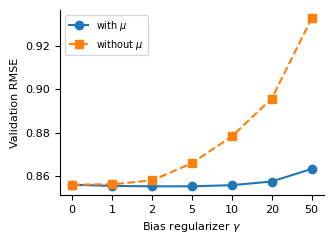

In [62]:
gammas = [0, 1, 2, 5, 10, 20, 50]
gamma_val = {"with_mu": [], "without_mu": []}
for use_mu, key in [(True, "with_mu"), (False, "without_mu")]:
    for gamma in gammas:
        _, h = train(data, 0, gamma=gamma, n_iterations=10, use_mu=use_mu,
                     parts=("train", "val"))
        gamma_val[key].append(h["val"][-1])
        print(f"{key}, gamma={gamma}: val RMSE {h['val'][-1]:.4f}")
best_gamma = gammas[int(np.argmin(gamma_val["with_mu"]))]
print("Best gamma:", best_gamma)
results["gamma"] = {"gammas": gammas, **gamma_val, "best": best_gamma}

plt.figure()
plt.plot(range(len(gammas)), gamma_val["with_mu"], "o-", label="with $\\mu$")
plt.plot(range(len(gammas)), gamma_val["without_mu"], "s--",
         label="without $\\mu$")
plt.xticks(range(len(gammas)), gammas)
plt.xlabel("Bias regularizer $\\gamma$")
plt.ylabel("Validation RMSE")
plt.legend()
plt.savefig("figures/p4_gamma.pdf")
plt.show()

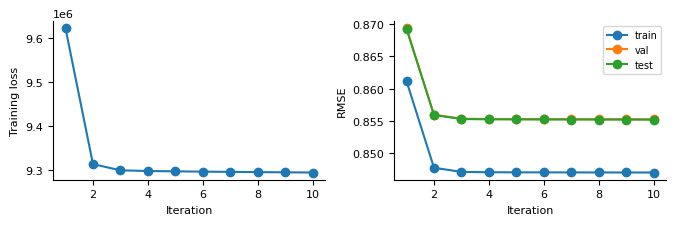

In [63]:
# The biases-only model with the chosen gamma
_, h_bias = train(data, 0, gamma=best_gamma, n_iterations=10)
results["biases_history"] = h_bias
fig, axes = plt.subplots(1, 2, figsize=(6.8, 2.3))
iterations = range(1, 11)
axes[0].plot(iterations, h_bias["loss"], "o-")
axes[0].set_ylabel("Training loss")
for name in ["train", "val", "test"]:
    axes[1].plot(iterations, h_bias[name], "o-", label=name)
axes[1].set_ylabel("RMSE")
axes[1].legend()
for ax in axes:
    ax.set_xlabel("Iteration")
plt.tight_layout()
plt.savefig("figures/p4_biases.pdf")
plt.show()
save()

## **Step 4:** Choosing τ and the number of iterations
For K = 16 I train with different τ for 40 iterations and record the validation RMSE after every iteration.

In [ ]:
taus = [0.5, 1, 2, 5, 10, 20, 50, 100]
tau_runs = {}
for tau in taus:
    _, h = train(data, 16, tau=tau, gamma=best_gamma, n_iterations=40,
                 parts=("train", "val"))
    tau_runs[tau] = h
    print(f"tau={tau}: train {h['train'][-1]:.4f}, val {h['val'][-1]:.4f}, "
          f"lowest val {min(h['val']):.4f} at iteration "
          f"{int(np.argmin(h['val'])) + 1}")
best_tau = min(taus, key=lambda tau: tau_runs[tau]["val"][-1])

# Number of iterations: the first one where the validation RMSE improves
# by less than 0.0001
gain = -np.diff(tau_runs[best_tau]["val"])
n_iterations = int(np.argmax(gain < 1e-4)) + 2 if np.any(gain < 1e-4) else 40
print("Best tau:", best_tau, " iterations:", n_iterations)
results["tau"] = {"taus": taus, "best": best_tau,
                  "n_iterations": n_iterations,
                  "runs": {str(tau): h for tau, h in tau_runs.items()}}

fig, axes = plt.subplots(1, 2, figsize=(6.8, 2.4))
axes[0].semilogx(taus, [tau_runs[t]["train"][-1] for t in taus], "o-",
                 label="train")
axes[0].semilogx(taus, [tau_runs[t]["val"][-1] for t in taus], "s-",
                 label="validation")
axes[0].set_xlabel("$\\tau$ (after 40 iterations)")
axes[0].set_ylabel("RMSE")
axes[0].legend()
for tau in taus:
    axes[1].plot(range(1, 41), tau_runs[tau]["val"], label=f"$\\tau$={tau}")
axes[1].axvline(n_iterations, color="gray", linestyle=":")
axes[1].set_ylim(0.765, 0.83)
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("Validation RMSE")
axes[1].legend(ncol=2)
plt.tight_layout()
plt.savefig("figures/p4_tau.pdf")
plt.show()

tau=0.5: train 0.6573, val 0.8056, lowest val 0.8037 at iteration 20


**About λ:** if λ, τ and γ are all multiplied by the same number, the loss is only scaled and its minimum does not move, so for ALS only τ/λ and γ/λ matter. I fix λ = 1 and check this below.

In [ ]:
lambda_val = []
for scale in [0.5, 1, 2]:
    _, h = train(data, 16, lam=scale, tau=scale * best_tau,
                 gamma=scale * best_gamma, n_iterations=n_iterations,
                 parts=("val",))
    lambda_val.append(h["val"][-1])
    print(f"lam={scale}: val RMSE {h['val'][-1]:.6f}")
results["lambda"] = lambda_val
save()

## **Step 5:** Choosing the number of latent dimensions K
K = 0, 2, 4, 8, 16, 32 (as in the lecture), each with a few values of τ.

In [ ]:
Ks = [0, 2, 4, 8, 16, 32]
K_runs = {}
for K in Ks:
    K_runs[K] = []
    for tau in ([5, 10, 20, 50] if K > 0 else [best_tau]):
        _, h = train(data, K, tau=tau, gamma=best_gamma,
                     n_iterations=n_iterations, parts=("train", "val"))
        K_runs[K].append({"tau": tau, "train": h["train"][-1],
                          "val": h["val"][-1], "time": np.mean(h["time"])})
    best = min(K_runs[K], key=lambda run: run["val"])
    print(f"K={K}: best tau {best['tau']}, val RMSE {best['val']:.4f}, "
          f"{best['time']:.1f} s per iteration")
best_K = {K: min(K_runs[K], key=lambda run: run["val"]) for K in Ks}
K_best = min(Ks, key=lambda K: best_K[K]["val"])
tau_best = best_K[K_best]["tau"]
tau_K2 = best_K[2]["tau"]
print("Chosen K:", K_best, " tau:", tau_best)

# K = 32 got the largest tau of the grid, and a large tau converges slowly,
# so I also give it tau = 50 and 100 with 40 iterations
K32 = {}
for tau in [50, 100]:
    _, h = train(data, 32, tau=tau, gamma=best_gamma, n_iterations=40,
                 parts=("val",))
    K32[tau] = h["val"][-1]
    print(f"K=32, tau={tau}, 40 iterations: val RMSE {h['val'][-1]:.4f}")
results["K"] = {"Ks": Ks, "runs": {str(K): K_runs[K] for K in Ks},
                "best": K_best, "tau_best": tau_best,
                "K32_40": {str(t): v for t, v in K32.items()},
                "K16_40": tau_runs[tau_best]["val"][-1]}

val_K = [best_K[K]["val"] for K in Ks]
plt.figure()
plt.plot(range(len(Ks)), [best_K[K]["train"] for K in Ks], "o-",
         label="train")
plt.plot(range(len(Ks)), val_K, "s-", label="validation")
for j in range(1, len(Ks)):
    plt.annotate(f"{val_K[j] - val_K[j - 1]:+.3f}", (j, val_K[j]),
                 textcoords="offset points", xytext=(0, 6), ha="center",
                 fontsize=6)
plt.xticks(range(len(Ks)), Ks)
plt.xlabel("Latent dimensions $K$ (best $\\tau$ for each)")
plt.ylabel("RMSE")
plt.legend(loc="lower left")
plt.savefig("figures/p4_K.pdf")
plt.show()
save()

## **Step 6:** Overfitting: K = 10 against K = 20
Both with a weak regularizer (τ = 0.5) and with the chosen τ; training and test RMSE after every iteration on the same axis.

In [ ]:
overfit = {}
for tau in [0.5, tau_best]:
    for K in [10, 20]:
        params, h = train(data, K, tau=tau, gamma=best_gamma,
                          n_iterations=n_iterations, parts=("train", "test"))
        overfit[(K, tau)] = params
        results.setdefault("overfit", {})[f"K{K}_tau{tau}"] = h
        print(f"K={K}, tau={tau}: train {h['train'][-1]:.4f}, "
              f"test {h['test'][-1]:.4f} (lowest test {min(h['test']):.4f} "
              f"at iteration {int(np.argmin(h['test'])) + 1})")

fig, axes = plt.subplots(1, 2, figsize=(6.8, 2.4), sharey=True)
for ax, tau in zip(axes, [0.5, tau_best]):
    for K, color in [(10, "C0"), (20, "C3")]:
        h = results["overfit"][f"K{K}_tau{tau}"]
        ax.plot(range(1, n_iterations + 1), h["train"], "--", color=color,
                label=f"K={K} train")
        ax.plot(range(1, n_iterations + 1), h["test"], "-", color=color,
                label=f"K={K} test")
    ax.set_title(f"$\\tau$ = {tau}", fontsize=8)
    ax.set_xlabel("Iteration")
axes[0].set_ylabel("RMSE")
axes[1].legend(ncol=2)
plt.tight_layout()
plt.savefig("figures/p4_overfitting.pdf")
plt.show()

In [ ]:
# Training and test RMSE for groups of users (and movies), by their number
# of training ratings
user_edges = [25, 50, 100, 200, 500, 1000]
user_labels = ["<25", "25-49", "50-99", "100-199", "200-499", "500-999",
               "1000+"]
item_edges = [1, 6, 21, 101, 1001, 10001]
item_labels = ["0", "1-5", "6-20", "21-100", "101-1k", "1k-10k", "10k+"]


def rmse_groups(sets, params, side, edges):
    U, V, user_biases, item_biases, mu = params
    args = ((U, user_biases, V, item_biases, mu) if side == "user"
            else (V, item_biases, U, user_biases, mu))
    group = np.digitize(np.diff(sets["train"]["by_" + side][0]), edges)
    out = {}
    for name in ["train", "test"]:
        ptr = sets[name]["by_" + side][0]
        sse = squared_errors(*sets[name]["by_" + side], *args)
        count = np.bincount(group, np.diff(ptr), minlength=len(edges) + 1)
        out[name] = np.sqrt(np.bincount(group, sse, minlength=len(edges) + 1)
                            / np.maximum(count, 1)).tolist()
        out[name + "_count"] = count.tolist()
    return out


groups = {}
fig, axes = plt.subplots(1, 2, figsize=(6.8, 2.5), sharey=True)
for ax, side, edges, labels in [(axes[0], "user", user_edges, user_labels),
                                (axes[1], "item", item_edges, item_labels)]:
    for (K, tau), color in [((20, 0.5), "C3"), ((20, tau_best), "C2"),
                            ((10, 0.5), "C0")]:
        g = rmse_groups(data, overfit[(K, tau)], side, edges)
        groups[f"{side}_K{K}_tau{tau}"] = g
        x = np.arange(len(labels))
        has_train = np.array(g["train_count"]) > 0
        ax.plot(x, g["test"], "o-", color=color,
                label=f"K={K}, $\\tau$={tau}")
        ax.plot(x[has_train], np.array(g["train"])[has_train], "x--",
                color=color, alpha=0.6)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=35)
    ax.set_xlabel("Training ratings per "
                  + ("user" if side == "user" else "movie"))
axes[0].set_ylabel("RMSE (solid: test, dashed: train)")
axes[1].legend()
plt.tight_layout()
plt.savefig("figures/p4_groups.pdf")
plt.show()
results["groups"] = groups
for key, g in groups.items():
    print(key, "train", np.round(g["train"], 3),
          "test", np.round(g["test"], 3))
del overfit
gc.collect()
save()

## **Step 7:** Final test RMSE (random and time split)
With λ, τ, γ, K and the number of iterations chosen on the validation set, I report the test RMSE once, for both splits. As a baseline I also predict the mean training rating μ for everything, and I compute R² = 1 − MSE / Var(test ratings).

In [ ]:
final = {}
for split_name in ["random", "time"]:
    sets = data if split_name == "random" else make_sets(time_split())
    test = sets["test"]["by_user"][2]
    mu_train = sets["train"]["by_user"][2].mean()
    final[split_name] = {"var": float(test.var()),
                         "mean_train": float(mu_train),
                         "mean_test": float(test.mean()),
                         "mean": float(np.sqrt(np.mean((test - mu_train)
                                                       ** 2)))}
    for model, K in [("biases", 0), ("full", K_best)]:
        params, h = train(sets, K, tau=tau_best, gamma=best_gamma,
                          n_iterations=n_iterations)
        final[split_name][model] = {name: h[name][-1]
                                    for name in ["train", "val", "test"]}
        if split_name == "random" and model == "full":
            params_random = params          # kept for later use
    del sets
    gc.collect()

for split_name, f in final.items():
    for model in ["mean", "biases", "full"]:
        test_rmse = f[model] if model == "mean" else f[model]["test"]
        print(f"{split_name}, {model}: test RMSE {test_rmse:.4f}, "
              f"R2 {1 - test_rmse ** 2 / f['var']:.3f}")
results["final"] = final
save()

## **Step 8:** Training on all 32M ratings
With the chosen settings I train on all the ratings (nothing held out). This model is used for the recommendations below.

In [ ]:
full_data = {"train": {
    "by_user": to_csr(user_index, item_index, all_ratings, M),
    "by_item": to_csr(item_index, user_index, all_ratings, N),
    "n": len(all_ratings)}}
(U_full, V_full, user_biases_full, item_biases_full,
 mu_full), h_full = train(full_data, K_best, tau=tau_best, gamma=best_gamma,
                          n_iterations=n_iterations, parts=("train",))
results["full_model"] = {"train": h_full["train"][-1],
                         "time": float(np.sum(h_full["time"])),
                         "time_per_iteration": float(np.mean(h_full["time"]))}
print(f"Train RMSE {h_full['train'][-1]:.4f}, "
      f"{np.sum(h_full['time']) / 60:.1f} minutes")

movies = pd.read_csv("ml-32m/movies.csv").set_index("movieId")
titles = movies.loc[index_to_item, "title"].to_numpy()
genres = movies.loc[index_to_item, "genres"].to_numpy()
ratings_per_movie = np.diff(full_data["train"]["by_item"][0])


def find_movie(title):
    return int(np.where(titles == title)[0][0])

## **Step 9:** A dummy user who liked *The Lord of the Rings*
The dummy user gives 5 stars to *The Fellowship of the Ring*. I fit the user's bias and trait vector with the same ALS updates (the movies stay fixed), and rank the movies by `u·v_n + w·b_n` (the user bias does not change the ranking). As in the lecture I try w = 1, w = 0.05, and w = 0.05 with only movies that have at least 100 ratings.

In [ ]:
def fit_new_user(liked, n_steps=10):
    u, bias = np.zeros(K_best), 0.0
    for _ in range(n_steps):
        bias = (sum(r - mu_full - item_biases_full[n] - u @ V_full[n]
                    for n, r in liked) / (len(liked) + best_gamma))
        A, b = tau_best * np.eye(K_best), np.zeros(K_best)
        for n, r in liked:
            A += np.outer(V_full[n], V_full[n])
            b += V_full[n] * (r - mu_full - bias - item_biases_full[n])
        u = np.linalg.solve(A, b)
    return u, bias


def recommend(title, w=0.05, min_ratings=100):
    liked = find_movie(title)
    u, bias = fit_new_user([(liked, 5.0)])
    score = V_full @ u + w * item_biases_full
    score[ratings_per_movie < min_ratings] = -np.inf
    score[liked] = -np.inf
    return [str(titles[n]) for n in np.argsort(-score)[:10]], u, bias


lotr = "Lord of the Rings: The Fellowship of the Ring, The (2001)"
dummy = {"w=1": recommend(lotr, 1, 0)[0],
         "w=0.05": recommend(lotr, 0.05, 0)[0]}
dummy["w=0.05, 100+ ratings"], u_dummy, bias_dummy = recommend(lotr)
for title in ["Toy Story (1995)", "Shining, The (1980)"]:
    dummy[title] = recommend(title)[0]
results["dummy"] = dummy
results["dummy_user"] = {"bias": bias_dummy,
                         "norm": float(np.linalg.norm(u_dummy))}
pd.DataFrame(dummy, index=range(1, 11))

## **Step 10:** Polarizing movies
A polarizing movie has a long trait vector v_n: u_m·v_n is then very positive for some users and very negative for others, so knowing if a user likes it says a lot about their taste. A movie with a short v_n is predicted almost only from the biases. Rare movies have short vectors because τ shrinks them, so to avoid overfitting being the explanation I only use movies with at least 1,000 ratings, and I check the claim against the spread (standard deviation) of each movie's ratings.

In [ ]:
length = np.linalg.norm(V_full, axis=1)
stats = pd.Series(all_ratings).groupby(item_index).agg(["mean", "std"])
popular = np.where(ratings_per_movie >= 1000)[0]
order = popular[np.argsort(-length[popular])]


def movie_table(items):
    return pd.DataFrame({"title": titles[items],
                         "|v|": length[items].round(2),
                         "ratings": ratings_per_movie[items],
                         "mean": stats["mean"].to_numpy()[items].round(2),
                         "std": stats["std"].to_numpy()[items].round(2)})


std = stats["std"].to_numpy()
results["polarizing"] = {
    "most": movie_table(order[:10]).to_dict(orient="list"),
    "least": movie_table(order[-10:][::-1]).to_dict(orient="list"),
    "n_popular": len(popular),
    "std_top50": float(std[order[:50]].mean()),
    "std_bottom50": float(std[order[-50:]].mean()),
    "corr": float(np.corrcoef(length[popular], std[popular])[0, 1])}
print({k: v for k, v in results["polarizing"].items()
       if k not in ["most", "least"]})
movie_table(order[:10])

In [ ]:
movie_table(order[-10:][::-1])

In [ ]:
plt.figure()
plt.semilogx(ratings_per_movie, length, ".", markersize=1, alpha=0.3,
             color="gray", rasterized=True)
plt.semilogx(ratings_per_movie[order[:10]], length[order[:10]], "o",
             markersize=3, color="C3", label="10 most polarizing")
plt.semilogx(ratings_per_movie[order[-10:]], length[order[-10:]], "o",
             markersize=3, color="C0", label="10 least polarizing")
plt.axvline(1000, color="black", linestyle=":", linewidth=0.8)
plt.xlabel("Number of ratings of the movie")
plt.ylabel("$\\|\\mathbf{v}_n\\|$")
plt.legend()
plt.savefig("figures/p4_polarizing.pdf", dpi=300)
plt.show()
save()

## **Step 11:** 2D embedding of the movies (K = 2)
The model with biases and K = 2, trained on all the ratings. I plot v_n for some well-known movies (the gray points are all movies with at least 100 ratings). Only the relative positions matter, since rotating U and V together does not change any prediction.

In [ ]:
(_, V_2d, _, _, _), _ = train(full_data, 2, tau=tau_K2, gamma=best_gamma,
                              n_iterations=n_iterations, parts=())
selection = [
    "Toy Story (1995)", "Finding Nemo (2003)", "Frozen (2013)",
    "Lion King, The (1994)", "Shrek (2001)", "Titanic (1997)",
    "Notebook, The (2004)", "Twilight (2008)", "Pretty Woman (1990)",
    "Saw (2004)", "Hostel (2005)", "Pulp Fiction (1994)",
    "Fight Club (1999)", "Big Lebowski, The (1998)",
    "Mulholland Drive (2001)", "Eraserhead (1977)",
    "2001: A Space Odyssey (1968)", "Casablanca (1942)",
    "Citizen Kane (1941)", "Transformers (2007)", "Armageddon (1998)",
    "Pearl Harbor (2001)", "Fast and the Furious, The (2001)", lotr,
    "Star Wars: Episode IV - A New Hope (1977)"]

try:
    from adjustText import adjust_text   # !pip install adjustText
except ImportError:
    adjust_text = None

plt.figure(figsize=(6.8, 4.2))
background = ratings_per_movie >= 100
plt.scatter(V_2d[background, 0], V_2d[background, 1], s=1,
            color="lightgray", alpha=0.4, rasterized=True)
labels = []
for title in selection:
    n = find_movie(title)
    plt.scatter(V_2d[n, 0], V_2d[n, 1], s=10, color="C0")
    labels.append(plt.text(V_2d[n, 0], V_2d[n, 1],
                           title.split(" (")[0].replace(", The", ""),
                           fontsize=6.5))
if adjust_text:
    adjust_text(labels, arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))
plt.xlabel("$v_{n1}$")
plt.ylabel("$v_{n2}$")
plt.savefig("figures/p4_embedding.pdf", dpi=300)
plt.show()
results["embedding"] = {title: V_2d[find_movie(title)].round(3).tolist()
                        for title in selection}
save()